# Supplementary Figure S6d. SCENIC regulon trans-MaxPIP annotations

Heritability enrichment, marginal τ* and joint τ* of trans-MaxPIP annotations built from cell-type-resolved SCENIC regulons with four program representations (TransMap = WPC, TransPCO*, AUCell, Eigengene = PC1); joint τ* comes from one model with the four annotations (`Joint_SCENIC_Regulon_Trans_Methods`). Source: `Functional_Program_comparison/sLDSC_SCENIC_Regulon.ipynb` cells 57-69 and `Manu_Figures/Figure2_Function_Program.ipynb` cell 12.

Error bars are estimate ± 1.96 × SE (95% CI), as drawn by the source helpers `plotEnrichForest` / `plotTauForest` (sldsc_utils.R). Significance symbols follow the source `pToSymbol`: **** P < 1e-4, *** P < 1e-3, ** P < 0.01, * P < 0.05, . P < 0.1, shown only when the estimate is > 0 (also for enrichment, whose null is 1). P-values are nominal and two-sided; no multiple-testing correction is applied (the rds also carries `fdr_bh`, a Benjamini–Hochberg adjustment across all tests of the same metric in the panel, for reference only). Dashed lines: 1 for enrichment, 0 for τ*. All S-LDSC values are random-effects meta-analyses across traits (57 all, 18 brain, 22 blood; per-trait models conditional on the 53 baseline-LD annotations), recomputed here from the per-trait S-LDSC outputs with a re-implementation of the author's meta-analysis code.

Integrity note: the source notebook reads `sLDSC_SCENIC_Regulon_Joint_Trans_Methods.rds`, written by `sLDSC_SCENIC_Regulon.ipynb` after cells 63-65 swapped the estimate, SE, P-value and symbol of TransMap (wPC) and TransPCO* (aPC) for the blood-trait meta-analysis only, in all three metrics. The swap is not a label fix: the per-trait S-LDSC `.results` files name the coefficients `SCENIC_Regulon_wPC_Remove` and `SCENIC_Regulon_aPC_Remove` in the expected order, the single-annotation models are separate runs, and the all/brain rows were left unswapped. The same SCENIC wPC marginal τ* (blood) is 0.046 (P = 0.15) in the untouched `sLDSC_TransMap_Functional_Methods.rds` (panel e) but 0.132 (P = 3e-5) in the swapped file. The values here are the unswapped meta-analysis results; for blood traits TransMap has enrichment 1.48 (P = 0.17), marginal τ* 0.046 (P = 0.15) and joint τ* 0.005 (P = 0.91), while TransPCO* has 2.42 / 0.132 / 0.275.

Input: `data/Figure_S6d_scenic_sldsc.rds`.

In [1]:
library(ggplot2)
library(patchwork)
d <- readRDS("data/Figure_S6d_scenic_sldsc.rds")
d

metric,trait_set,trait,method,annotation_raw,est,se,pvalue,fdr_bh,n_traits
<fct>,<chr>,<fct>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Enrichment,all_traits,All traits (57),TransMap,SCENIC_Regulon_wPC,2.483832838,0.14269457,6.391368e-11,3.834821e-10,57
Enrichment,blood_traits,Blood-related traits (22),TransMap,SCENIC_Regulon_wPC,1.479514705,0.26015992,1.674093e-01,1.955676e-01,22
Enrichment,brain_traits,Brain-related traits (18),TransMap,SCENIC_Regulon_wPC,2.989725546,0.22682753,2.675077e-08,1.070031e-07,18
Enrichment,all_traits,All traits (57),TransPCO*,SCENIC_Regulon_aPC,2.727699625,0.16650933,6.232284e-13,7.478741e-12,57
Enrichment,blood_traits,Blood-related traits (22),TransPCO*,SCENIC_Regulon_aPC,2.422363159,0.31480797,2.188727e-03,4.377455e-03,22
Enrichment,brain_traits,Brain-related traits (18),TransPCO*,SCENIC_Regulon_aPC,2.918881518,0.28643710,6.756432e-07,2.026930e-06,18
Enrichment,all_traits,All traits (57),AUCell,SCENIC_Regulon_AUCell,2.033189533,0.31578969,5.316230e-03,7.974345e-03,57
Enrichment,blood_traits,Blood-related traits (22),AUCell,SCENIC_Regulon_AUCell,0.599877277,0.62764549,7.950394e-01,7.950394e-01,22
Enrichment,brain_traits,Brain-related traits (18),AUCell,SCENIC_Regulon_AUCell,3.228304914,0.46767435,1.548607e-04,3.716656e-04,18


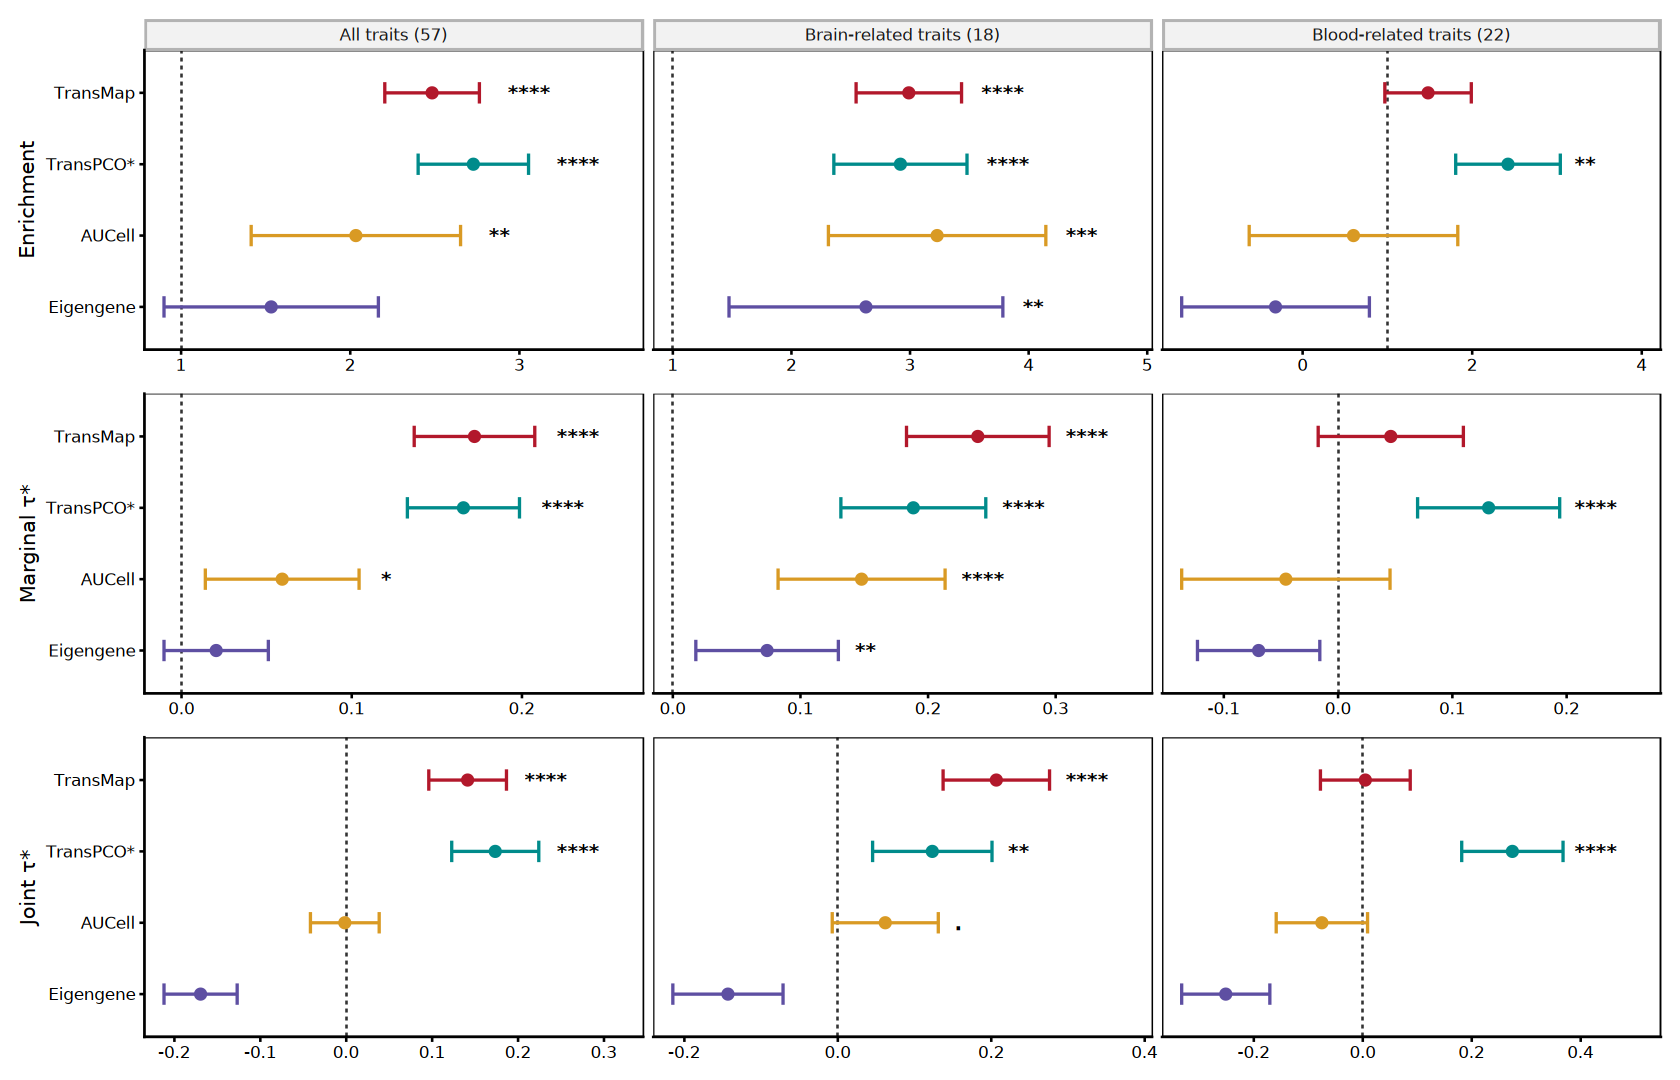

In [2]:
p_sym <- function(p, est) {
  s <- c("****", "***", "**", "*", ".", "")[findInterval(p, c(0, 1e-4, 1e-3, 0.01, 0.05, 0.1, Inf), rightmost.closed = TRUE)]
  ifelse(est > 0, s, "")
}
forest <- function(d, cols, ylab, vline, show_strip = TRUE) {
  d$lo <- d$est - 1.96 * d$se; d$hi <- d$est + 1.96 * d$se
  d$sym <- p_sym(d$pvalue, d$est)
  pad <- 0.03 * diff(range(c(d$lo, d$hi, vline)))
  p <- ggplot(d, aes(y = annotation, colour = annotation)) +
    geom_vline(xintercept = vline, linetype = "dashed", colour = "grey20") +
    geom_errorbar(aes(xmin = lo, xmax = hi), width = 0.3, orientation = "y", linewidth = 0.7) +
    geom_point(aes(x = est), size = 2.6) +
    geom_text(aes(x = hi + pad, label = sym), colour = "black", hjust = 0, size = 4.2, fontface = "bold") +
    facet_grid(. ~ trait, scales = "free_x") +
    scale_colour_manual(values = cols, guide = "none") +
    scale_y_discrete(limits = rev) +
    scale_x_continuous(expand = expansion(mult = c(0.05, 0.22))) +
    labs(x = NULL, y = ylab) +
    theme_classic(base_size = 12) +
    theme(strip.background = element_rect(fill = "grey95", colour = "grey70"),
          panel.border = element_rect(colour = "black", fill = NA, linewidth = 0.4))
  if (!show_strip) p <- p + theme(strip.text = element_blank(), strip.background = element_blank())
  p
}

cols <- c("TransMap" = "#B2182B", "TransPCO*" = "#008B8B", "AUCell" = "#D99A24", "Eigengene" = "#5E4FA2")
GROUP <- "method"

d$annotation <- d[[GROUP]]
rows <- list(
  forest(subset(d, metric == "Enrichment"), cols, "Enrichment", 1, TRUE),
  forest(subset(d, metric == "Marginal tau*"), cols, expression("Marginal " * tau * "*"), 0, FALSE),
  forest(subset(d, metric == "Joint tau*"), cols, expression("Joint " * tau * "*"), 0, FALSE))
options(repr.plot.width = 14, repr.plot.height = 9)
wrap_plots(rows, ncol = 1)